# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)

In [2]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[8, 5, 7, 1, 6, 9, 0, 4, 3, 2]

In [3]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [4]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(5.348966232881374)

Tour length: 5.35


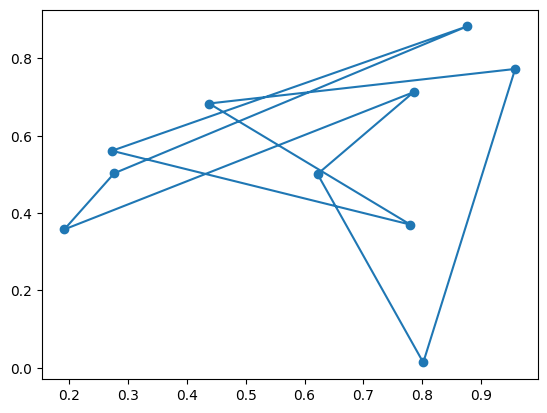

In [5]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

### BÀI 7 - KIỂM TRA DỮ LIỆU TSP

Số thành phố: 10
Tour ban đầu: [2, 8, 3, 5, 6, 4, 9, 0, 1, 7]
Chiều dài tour ban đầu: 4.943798767765629
Tour length: 4.94


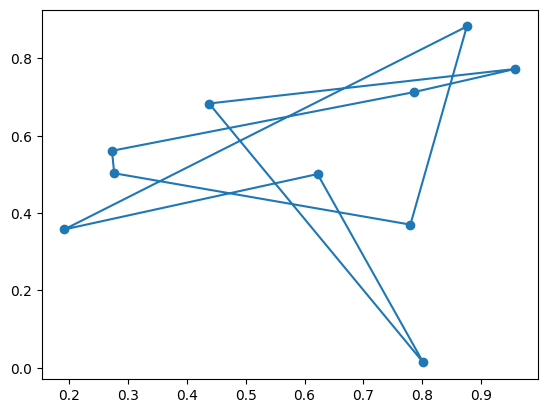

In [6]:
import random
import numpy as np

random.seed(1234)
np.random.seed(1234)

# Khởi tạo bài toán gồm 10 thành phố
tsp = random_tsp(10)

# Tạo hành trình ngẫu nhiên
initial_tour = random_tour(10)

# Tính chiều dài hành trình
initial_length = tour_length(tsp, initial_tour)

print("Số thành phố:", 10)
print("Tour ban đầu:", initial_tour)
print("Chiều dài tour ban đầu:", initial_length)

# Hiển thị tour ban đầu
show_tsp(tsp, initial_tour)

### BÀI 7 - TOÁN TỬ LÂN CẬN SWAP

**Biểu diễn trạng thái:** Mỗi trạng thái là một hoán vị của
n thành phố, trong đó mỗi thành phố xuất hiện đúng một lần.
Điểm xuất phát được nối lại với điểm kết thúc để tạo thành
một chu trình khép kín.

**Hàm mục tiêu:** Tối thiểu hóa tổng chiều dài hành trình,
bao gồm khoảng cách giữa các thành phố liên tiếp và khoảng
cách từ thành phố cuối cùng về thành phố đầu tiên.

**Toán tử lân cận Swap:** Chọn hai vị trí i và j khác nhau
trong tour và hoán đổi hai thành phố tại các vị trí đó.
Phép hoán đổi không làm mất hoặc lặp thành phố nên luôn
tạo ra một tour hợp lệ.

**Số lượng lân cận:** Với n thành phố, số phép Swap phân
biệt là n(n - 1)/2. Khi n = 10, có 45 lân cận.

**Tính thống nhất:** Cả năm thuật toán tìm kiếm cục bộ
đều sử dụng toán tử Swap để tạo trạng thái lân cận.

In [7]:
def swap_neighbor(tour, i, j):
    new_tour = list(tour).copy()

    new_tour[i], new_tour[j] = (
        new_tour[j], new_tour[i]
    )

    return new_tour


# Kiểm tra toán tử swap
test_tour = swap_neighbor(initial_tour, 1, 3)

print("Tour ban đầu:", initial_tour)
print("Tour sau swap:", test_tour)

print("Chiều dài ban đầu:", tour_length(tsp, initial_tour))
print("Chiều dài sau swap:", tour_length(tsp, test_tour))

Tour ban đầu: [2, 8, 3, 5, 6, 4, 9, 0, 1, 7]
Tour sau swap: [2, 5, 3, 8, 6, 4, 9, 0, 1, 7]
Chiều dài ban đầu: 4.943798767765629
Chiều dài sau swap: 5.296105147813016


## Steepest-ascend Hill Climbing Search [3 Points]

Evaluate all neighboring tours generated by swapping two cities. Select the neighbor with the shortest tour length if it improves the current solution. Stop when no improving neighbor exists.

Tour ban đầu: [2, 8, 3, 5, 6, 4, 9, 0, 1, 7]
Chiều dài ban đầu: 4.943798767765629

Tour sau tối ưu: [4, 8, 9, 3, 2, 5, 6, 0, 1, 7]
Chiều dài sau tối ưu: 2.8810894251962416
Số vòng lặp: 5
Số lần đánh giá: 270
Tour length: 2.88


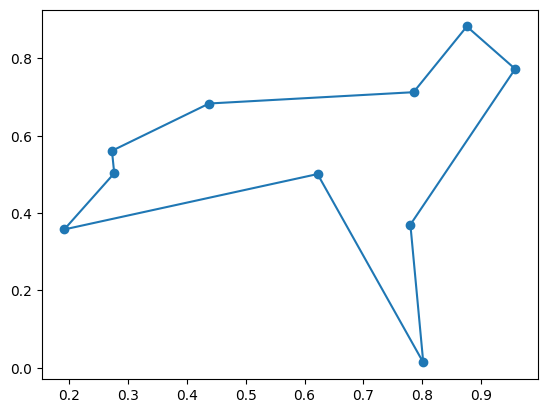

In [8]:
# Code goes here
# BÀI 7 - STEEPEST-ASCENT HILL CLIMBING (TSP)

def steepest_hill_climbing(tsp, initial_tour):
    current_tour = list(initial_tour)
    current_length = tour_length(tsp, current_tour)

    iterations = 0
    evaluations = 0
    history = [current_length]

    n = len(current_tour)

    while True:
        best_tour = current_tour
        best_length = current_length

        # Xét tất cả cặp thành phố có thể hoán đổi
        for i in range(n - 1):
            for j in range(i + 1, n):
                neighbor = swap_neighbor(current_tour, i, j)
                neighbor_length = tour_length(tsp, neighbor)
                evaluations += 1

                if neighbor_length < best_length:
                    best_tour = neighbor
                    best_length = neighbor_length

        # Không còn lân cận nào cải thiện
        if best_length >= current_length:
            break

        current_tour = best_tour
        current_length = best_length

        iterations += 1
        history.append(current_length)

    return {
        "tour": current_tour,
        "length": current_length,
        "iterations": iterations,
        "evaluations": evaluations,
        "history": history
    }


# Chạy thử thuật toán
result_steepest = steepest_hill_climbing(tsp, initial_tour)

print("Tour ban đầu:", initial_tour)
print("Chiều dài ban đầu:", initial_length)

print("\nTour sau tối ưu:", result_steepest["tour"])
print("Chiều dài sau tối ưu:", result_steepest["length"])
print("Số vòng lặp:", result_steepest["iterations"])
print("Số lần đánh giá:", result_steepest["evaluations"])

show_tsp(tsp, result_steepest["tour"])

## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

Số thành phố: 10
Chiều dài Steepest: 2.8810894251962416
Chiều dài Random Restarts: 2.763573577757701
Tour tốt nhất: [9, 8, 3, 1, 4, 7, 0, 6, 5, 2]
Số lần khởi tạo: 20
Tổng số vòng lặp: 100
Tổng số lần đánh giá: 5400
Tour length: 2.76


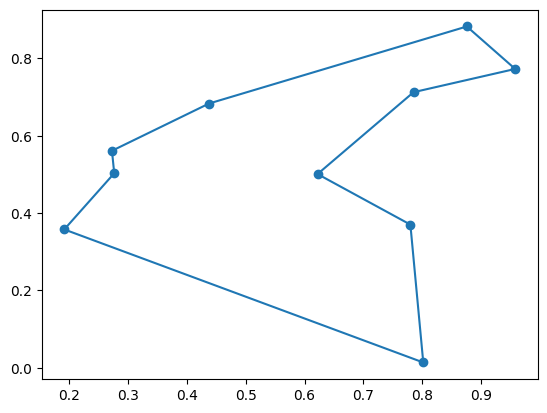

In [9]:
# Code goes here
# BÀI 7 - RANDOM RESTARTS (TSP)

def random_restarts(tsp, n_restarts=20):
    best_result = None
    total_evaluations = 0
    total_iterations = 0

    # Lấy đúng số thành phố từ dữ liệu
    n = len(tsp["pos"])

    for _ in range(n_restarts):
        start_tour = random_tour(n)

        result = steepest_hill_climbing(tsp, start_tour)

        total_evaluations += result["evaluations"]
        total_iterations += result["iterations"]

        if best_result is None or result["length"] < best_result["length"]:
            best_result = result

    return {
        "tour": best_result["tour"],
        "length": best_result["length"],
        "iterations": total_iterations,
        "evaluations": total_evaluations,
        "restarts": n_restarts
    }


# Chạy lại Random Restarts
random.seed(1234)

result_restart = random_restarts(tsp, n_restarts=20)

print("Số thành phố:", len(tsp["pos"]))
print("Chiều dài Steepest:", result_steepest["length"])
print("Chiều dài Random Restarts:", result_restart["length"])
print("Tour tốt nhất:", result_restart["tour"])
print("Số lần khởi tạo:", result_restart["restarts"])
print("Tổng số vòng lặp:", result_restart["iterations"])
print("Tổng số lần đánh giá:", result_restart["evaluations"])

show_tsp(tsp, result_restart["tour"])

## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

Số thành phố: 10
Chiều dài ban đầu: 4.943798767765629
Chiều dài Stochastic: 2.9062078251965877
Tour sau tối ưu: [7, 1, 0, 6, 5, 2, 9, 8, 3, 4]
Số vòng lặp: 14
Số lần đánh giá: 675
Tour length: 2.91


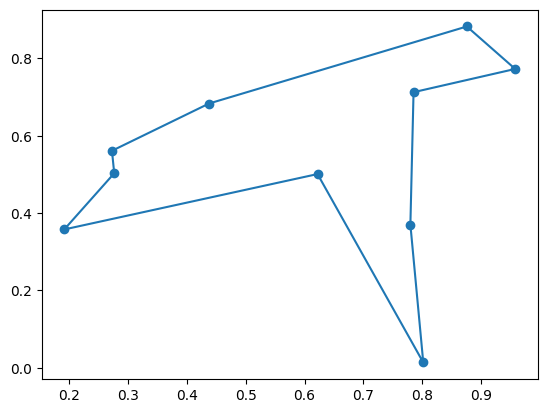

In [10]:
# Code goes here
# BÀI 7 - STOCHASTIC HILL CLIMBING (TSP)

def stochastic_hill_climbing(tsp, initial_tour):
    current_tour = list(initial_tour)
    current_length = tour_length(tsp, current_tour)

    iterations = 0
    evaluations = 0
    history = [current_length]

    n = len(current_tour)

    while True:
        improving_neighbors = []

        # Xét tất cả các trạng thái lân cận bằng Swap
        for i in range(n - 1):
            for j in range(i + 1, n):
                neighbor = swap_neighbor(current_tour, i, j)
                neighbor_length = tour_length(tsp, neighbor)

                evaluations += 1

                if neighbor_length < current_length:
                    improving_neighbors.append(
                        (neighbor, neighbor_length)
                    )

        # Không còn trạng thái cải thiện
        if not improving_neighbors:
            break

        # Chọn ngẫu nhiên một trạng thái cải thiện
        current_tour, current_length = random.choice(
            improving_neighbors
        )

        iterations += 1
        history.append(current_length)

    return {
        "tour": current_tour,
        "length": current_length,
        "iterations": iterations,
        "evaluations": evaluations,
        "history": history
    }


# Chạy thử Stochastic Hill Climbing
random.seed(1234)

result_stochastic = stochastic_hill_climbing(tsp, initial_tour)

print("Số thành phố:", len(tsp["pos"]))
print("Chiều dài ban đầu:", initial_length)
print("Chiều dài Stochastic:", result_stochastic["length"])
print("Tour sau tối ưu:", result_stochastic["tour"])
print("Số vòng lặp:", result_stochastic["iterations"])
print("Số lần đánh giá:", result_stochastic["evaluations"])

show_tsp(tsp, result_stochastic["tour"])

## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

Số thành phố: 10
Chiều dài ban đầu: 4.943798767765629
Chiều dài First-choice: 2.8927329901889594
Tour sau tối ưu: [0, 5, 6, 2, 3, 9, 8, 1, 4, 7]
Số vòng lặp: 11
Số lần đánh giá: 286
Tour length: 2.89


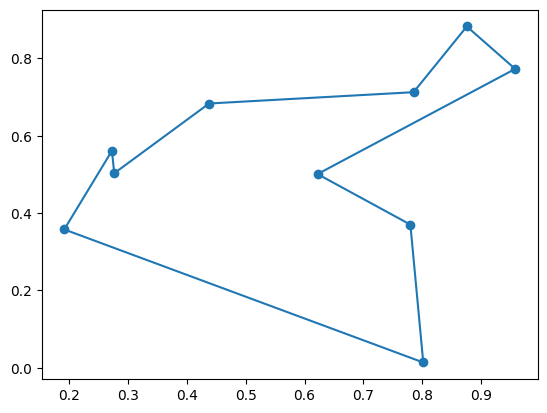

In [11]:
# Code goes here
# BÀI 7 - FIRST-CHOICE HILL CLIMBING (TSP)

def first_choice_hill_climbing(tsp, initial_tour, max_attempts=200):
    current_tour = list(initial_tour)
    current_length = tour_length(tsp, current_tour)

    iterations = 0
    evaluations = 0
    history = [current_length]

    n = len(current_tour)
    attempts_without_improvement = 0

    while attempts_without_improvement < max_attempts:
        # Chọn ngẫu nhiên hai vị trí khác nhau
        i, j = random.sample(range(n), 2)

        neighbor = swap_neighbor(current_tour, i, j)
        neighbor_length = tour_length(tsp, neighbor)
        evaluations += 1

        if neighbor_length < current_length:
            # Chấp nhận ngay lân cận đầu tiên cải thiện
            current_tour = neighbor
            current_length = neighbor_length

            iterations += 1
            history.append(current_length)
            attempts_without_improvement = 0
        else:
            attempts_without_improvement += 1

    return {
        "tour": current_tour,
        "length": current_length,
        "iterations": iterations,
        "evaluations": evaluations,
        "history": history
    }


# Chạy thử First-choice Hill Climbing
random.seed(1234)

result_first_choice = first_choice_hill_climbing(
    tsp,
    initial_tour,
    max_attempts=200
)

print("Số thành phố:", len(tsp["pos"]))
print("Chiều dài ban đầu:", initial_length)
print("Chiều dài First-choice:", result_first_choice["length"])
print("Tour sau tối ưu:", result_first_choice["tour"])
print("Số vòng lặp:", result_first_choice["iterations"])
print("Số lần đánh giá:", result_first_choice["evaluations"])

show_tsp(tsp, result_first_choice["tour"])

## Simulated Annealing [2 Points]

Số thành phố: 10
Chiều dài ban đầu: 4.943798767765629
Chiều dài Simulated Annealing: 2.763573577757701
Tour tốt nhất: [7, 4, 1, 3, 8, 9, 2, 5, 6, 0]
Số vòng lặp: 3675
Số lần đánh giá: 3675
Số bước được chấp nhận: 261
Tour length: 2.76


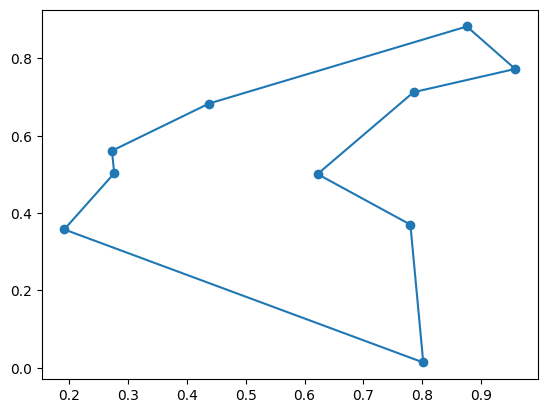

In [12]:
# Code goes here
# BÀI 7 - SIMULATED ANNEALING (TSP)

import math
import random

def simulated_annealing(
    tsp,
    initial_tour,
    T0=1.0,
    alpha=0.995,
    max_iterations=5000
):
    current_tour = list(initial_tour)
    current_length = tour_length(tsp, current_tour)

    best_tour = current_tour.copy()
    best_length = current_length

    temperature = T0
    evaluations = 0
    accepted_moves = 0
    history = [best_length]

    n = len(current_tour)

    for iteration in range(max_iterations):

        # Sinh trạng thái lân cận bằng toán tử Swap
        i, j = random.sample(range(n), 2)

        neighbor = swap_neighbor(current_tour, i, j)
        neighbor_length = tour_length(tsp, neighbor)
        evaluations += 1

        # Độ thay đổi của hàm mục tiêu
        delta = neighbor_length - current_length

        # Chấp nhận bước tốt hơn hoặc bước xấu hơn theo xác suất
        if delta < 0 or random.random() < math.exp(
            -delta / temperature
        ):
            current_tour = neighbor
            current_length = neighbor_length
            accepted_moves += 1

        # Ghi nhận tour tốt nhất từng tìm được
        if current_length < best_length:
            best_tour = current_tour.copy()
            best_length = current_length

        history.append(best_length)

        # Giảm nhiệt độ theo lịch hàm mũ
        temperature *= alpha

        if temperature < 1e-8:
            break

    return {
        "tour": best_tour,
        "length": best_length,
        "iterations": iteration + 1,
        "evaluations": evaluations,
        "accepted_moves": accepted_moves,
        "history": history
    }


# Chạy thử Simulated Annealing
random.seed(1234)

result_sa = simulated_annealing(
    tsp,
    initial_tour,
    T0=1.0,
    alpha=0.995,
    max_iterations=5000
)

print("Số thành phố:", len(tsp["pos"]))
print("Chiều dài ban đầu:", initial_length)
print("Chiều dài Simulated Annealing:", result_sa["length"])
print("Tour tốt nhất:", result_sa["tour"])
print("Số vòng lặp:", result_sa["iterations"])
print("Số lần đánh giá:", result_sa["evaluations"])
print("Số bước được chấp nhận:", result_sa["accepted_moves"])

show_tsp(tsp, result_sa["tour"])

## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [13]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.1785755157470703 milliseconds


In [14]:
# Code and results go here
# BÀI 7 - COMPARE PERFORMANCE: 10 THÀNH PHỐ

import time
import pandas as pd

algorithms = {
    "Steepest-ascent": lambda: steepest_hill_climbing(tsp, initial_tour),
    "Random Restarts": lambda: random_restarts(tsp, n_restarts=20),
    "Stochastic": lambda: stochastic_hill_climbing(tsp, initial_tour),
    "First-choice": lambda: first_choice_hill_climbing(
        tsp, initial_tour, max_attempts=200
    ),
    "Simulated Annealing": lambda: simulated_annealing(
        tsp, initial_tour, T0=1.0, alpha=0.995, max_iterations=5000
    )
}

comparison = []

for name, algorithm in algorithms.items():
    random.seed(1234)

    start = time.perf_counter()
    result = algorithm()
    elapsed = (time.perf_counter() - start) * 1000

    comparison.append({
        "Thuật toán": name,
        "Số thành phố": len(tsp["pos"]),
        "Chiều dài tour": round(result["length"], 4),
        "Số lần đánh giá": result["evaluations"],
        "Thời gian (ms)": round(elapsed, 3)
    })

df_compare = pd.DataFrame(comparison)
display(df_compare)

,Thuật toán,Số thành phố,Chiều dài tour,Số lần đánh giá,Thời gian (ms)
0,Steepest-ascent,10,2.88,270,0.83
1,Random Restarts,10,2.76,5400,11.66
2,Stochastic,10,2.91,675,1.31
3,First-choice,10,2.89,286,1.09
4,Simulated Annealing,10,2.76,3675,14.90


### BÀI 7 - SO SÁNH THEO SỐ THÀNH PHỐ

In [15]:
city_sizes = [10, 20, 30, 40]
scaling_results = []

for n in city_sizes:

    # Tạo dữ liệu TSP với n thành phố
    np.random.seed(1234)
    tsp_n = random_tsp(n)

    # Tạo cùng một tour ban đầu cho các thuật toán
    random.seed(1234)
    initial_tour_n = random_tour(n)

    algorithms_n = {
        "Steepest-ascent": lambda: steepest_hill_climbing(
            tsp_n, initial_tour_n
        ),
        "Random Restarts": lambda: random_restarts(
            tsp_n, n_restarts=20
        ),
        "Stochastic": lambda: stochastic_hill_climbing(
            tsp_n, initial_tour_n
        ),
        "First-choice": lambda: first_choice_hill_climbing(
            tsp_n, initial_tour_n, max_attempts=200
        ),
        "Simulated Annealing": lambda: simulated_annealing(
            tsp_n, initial_tour_n,
            T0=1.0, alpha=0.995, max_iterations=5000
        )
    }

    for name, algorithm in algorithms_n.items():

        random.seed(1234)

        start = time.perf_counter()
        result = algorithm()
        elapsed = (time.perf_counter() - start) * 1000

        scaling_results.append({
            "Số thành phố": n,
            "Thuật toán": name,
            "Chiều dài tour": round(result["length"], 4),
            "Số lần đánh giá": result["evaluations"],
            "Thời gian (ms)": round(elapsed, 3)
        })

    print(f"Đã hoàn thành: {n} thành phố")

df_scaling = pd.DataFrame(scaling_results)

display(df_scaling)

Đã hoàn thành: 10 thành phố
Đã hoàn thành: 20 thành phố
Đã hoàn thành: 30 thành phố
Đã hoàn thành: 40 thành phố


,Số thành phố,Thuật toán,Chiều dài tour,Số lần đánh giá,Thời gian (ms)
0,10,Steepest-ascent,2.88,270,0.55
1,10,Random Restarts,2.76,5400,10.93
2,10,Stochastic,2.91,675,1.30
3,10,First-choice,2.89,286,1.04
4,10,Simulated Annealing,2.76,3675,15.99
5,20,Steepest-ascent,4.76,2090,6.89
6,20,Random Restarts,4.14,53200,183.54
7,20,Stochastic,5.04,5510,18.20
8,20,First-choice,5.38,560,2.96
9,20,Simulated Annealing,4.95,3675,20.37


### BÀI 7 - BIỂU ĐỒ SO SÁNH CHIỀU DÀI TOUR

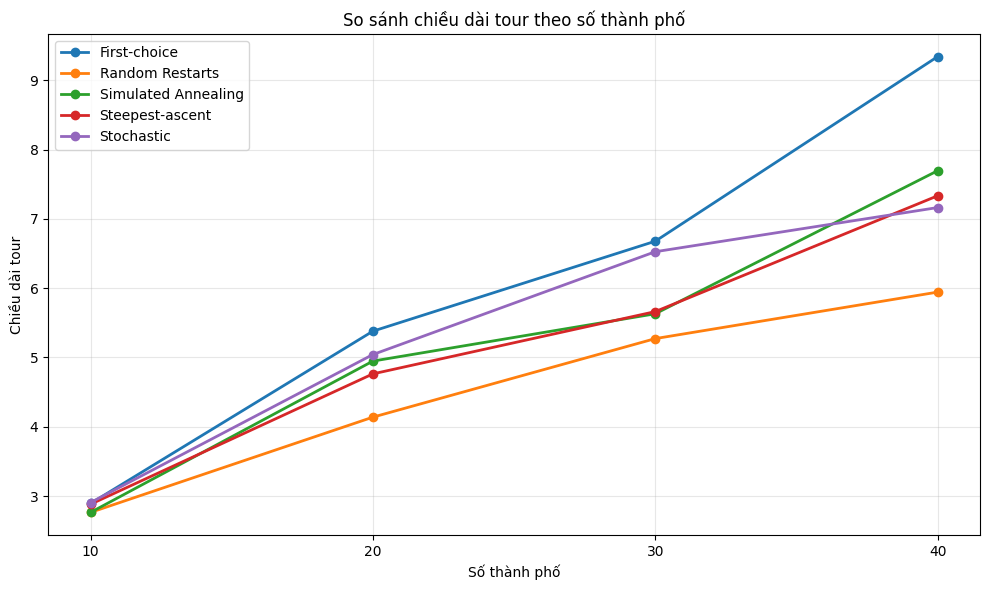

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, group in df_scaling.groupby("Thuật toán"):
    group = group.sort_values("Số thành phố")

    plt.plot(
        group["Số thành phố"],
        group["Chiều dài tour"],
        marker="o",
        linewidth=2,
        label=name
    )

plt.title("So sánh chiều dài tour theo số thành phố")
plt.xlabel("Số thành phố")
plt.ylabel("Chiều dài tour")
plt.xticks(city_sizes)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### BÀI 7 - BIỂU ĐỒ SO SÁNH THỜI GIAN THỰC THI

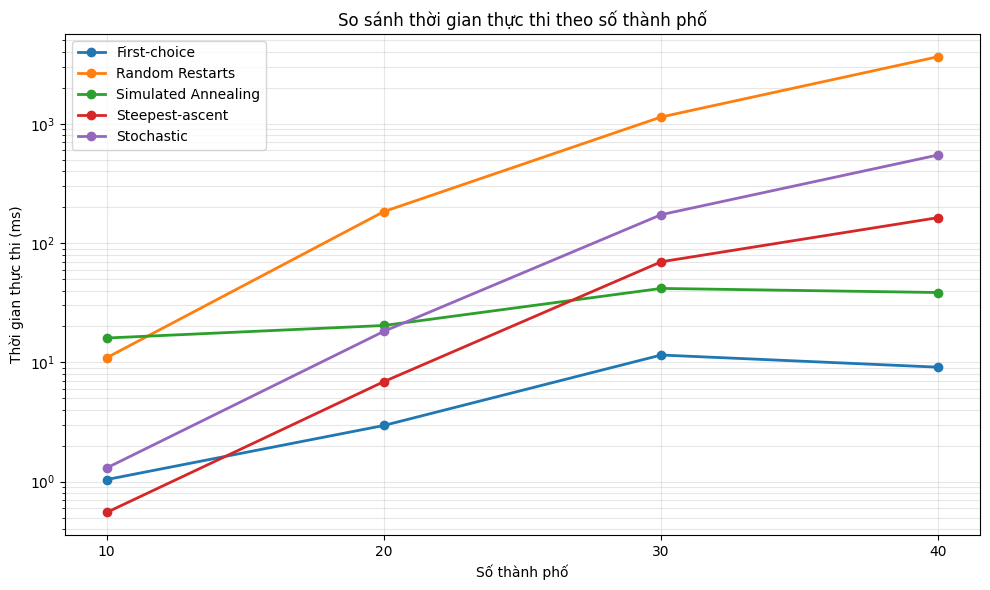

In [17]:
plt.figure(figsize=(10, 6))

for name, group in df_scaling.groupby("Thuật toán"):
    group = group.sort_values("Số thành phố")

    plt.plot(
        group["Số thành phố"],
        group["Thời gian (ms)"],
        marker="o",
        linewidth=2,
        label=name
    )

plt.title("So sánh thời gian thực thi theo số thành phố")
plt.xlabel("Số thành phố")
plt.ylabel("Thời gian thực thi (ms)")
plt.xticks(city_sizes)

# Dùng thang log vì thời gian giữa các thuật toán chênh lệch lớn
plt.yscale("log")

plt.legend()
plt.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()

### BÀI 7 - MINH HỌA TOUR TRƯỚC VÀ SAU TỐI ƯU

=== TOUR BAN ĐẦU ===
Chiều dài: 4.9438
Tour length: 4.94


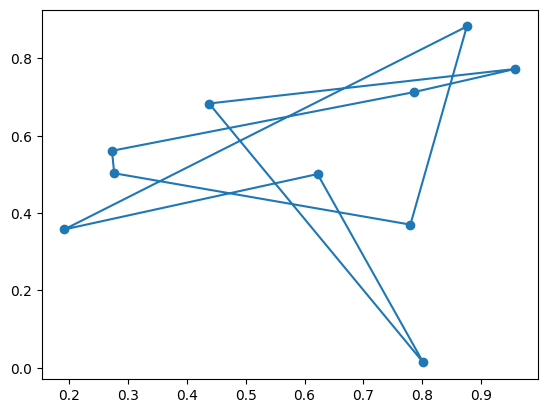


=== TOUR SAU RANDOM RESTARTS ===
Chiều dài: 2.7636
Tour length: 2.76


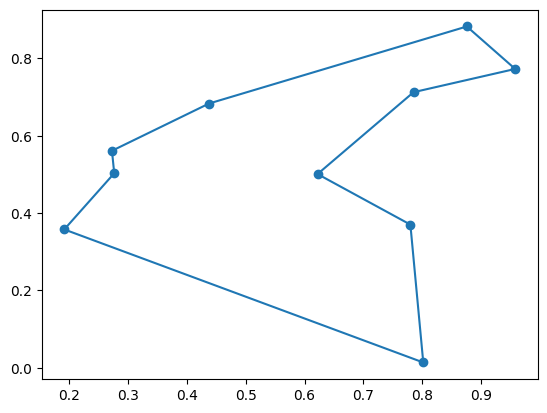

In [18]:
print("=== TOUR BAN ĐẦU ===")
print("Chiều dài:", round(initial_length, 4))
show_tsp(tsp, initial_tour)

print("\n=== TOUR SAU RANDOM RESTARTS ===")
print("Chiều dài:", round(result_restart["length"], 4))
show_tsp(tsp, result_restart["tour"])

## Bonus: Genetic Algorithm [+1 Point]

Số thành phố: 10
Chiều dài tour ban đầu: 4.943798767765629
Chiều dài Genetic Algorithm: 2.763573577757701
Tour tốt nhất: [2, 9, 8, 3, 1, 4, 7, 0, 6, 5]
Số thế hệ: 300
Số lần đánh giá: 30100
Tour length: 2.76


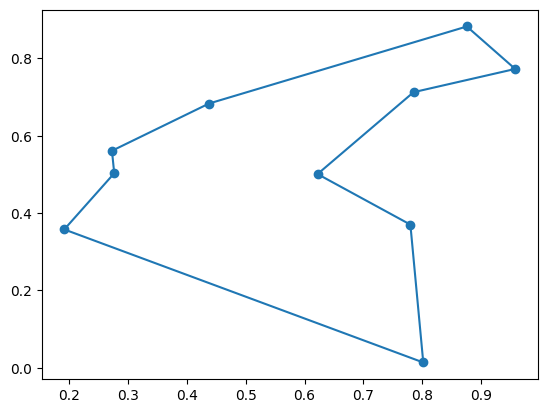

In [19]:
# Code goes here
# BÀI 7 - BONUS: GENETIC ALGORITHM CHO TSP

import random

# Chọn cá thể tốt nhất trong một nhóm ngẫu nhiên
def tournament_selection(population, tsp, k=3):
    candidates = random.sample(population, k)

    return min(
        candidates,
        key=lambda tour: tour_length(tsp, tour)
    ).copy()


# Lai ghép Order Crossover (OX)
def order_crossover(parent1, parent2):
    n = len(parent1)

    start, end = sorted(random.sample(range(n), 2))

    child = [None] * n

    # Giữ một đoạn từ cha thứ nhất
    child[start:end + 1] = parent1[start:end + 1]

    # Lấy các thành phố còn lại theo thứ tự của cha thứ hai
    remaining = [
        city for city in parent2
        if city not in child
    ]

    positions = list(range(end + 1, n)) + list(range(0, start))

    for pos, city in zip(positions, remaining):
        child[pos] = city

    return child


# Đột biến bằng toán tử Swap
def swap_mutation(tour, mutation_rate=0.1):
    new_tour = tour.copy()

    if random.random() < mutation_rate:
        i, j = random.sample(range(len(new_tour)), 2)
        new_tour = swap_neighbor(new_tour, i, j)

    return new_tour


# Thuật toán di truyền
def genetic_algorithm(
    tsp,
    population_size=100,
    generations=300,
    mutation_rate=0.1,
    elite_size=2
):
    n = len(tsp["pos"])

    # Tạo quần thể ban đầu
    population = [
        random_tour(n)
        for _ in range(population_size)
    ]

    best_tour = None
    best_length = float("inf")
    history = []
    evaluations = 0

    for generation in range(generations):

        # Đánh giá các cá thể
        scored = [
            (tour_length(tsp, tour), tour)
            for tour in population
        ]
        evaluations += len(population)

        scored.sort(key=lambda item: item[0])

        # Lưu cá thể tốt nhất từ trước tới nay
        if scored[0][0] < best_length:
            best_length = scored[0][0]
            best_tour = scored[0][1].copy()

        history.append(best_length)

        # Giữ lại các cá thể tốt nhất
        new_population = [
            tour.copy()
            for _, tour in scored[:elite_size]
        ]

        # Tạo thế hệ mới
        while len(new_population) < population_size:

            parent1 = tournament_selection(
                population, tsp
            )
            parent2 = tournament_selection(
                population, tsp
            )

            child = order_crossover(parent1, parent2)
            child = swap_mutation(child, mutation_rate)

            new_population.append(child)

        population = new_population

    # Đánh giá quần thể cuối cùng
    for tour in population:
        length = tour_length(tsp, tour)
        evaluations += 1

        if length < best_length:
            best_length = length
            best_tour = tour.copy()

    history.append(best_length)

    return {
        "tour": best_tour,
        "length": best_length,
        "generations": generations,
        "evaluations": evaluations,
        "history": history
    }


# CHẠY THỬ GENETIC ALGORITHM VỚI 10 THÀNH PHỐ

random.seed(1234)

result_ga = genetic_algorithm(
    tsp,
    population_size=100,
    generations=300,
    mutation_rate=0.1,
    elite_size=2
)

print("Số thành phố:", len(tsp["pos"]))
print("Chiều dài tour ban đầu:", initial_length)
print("Chiều dài Genetic Algorithm:", result_ga["length"])
print("Tour tốt nhất:", result_ga["tour"])
print("Số thế hệ:", result_ga["generations"])
print("Số lần đánh giá:", result_ga["evaluations"])

show_tsp(tsp, result_ga["tour"])

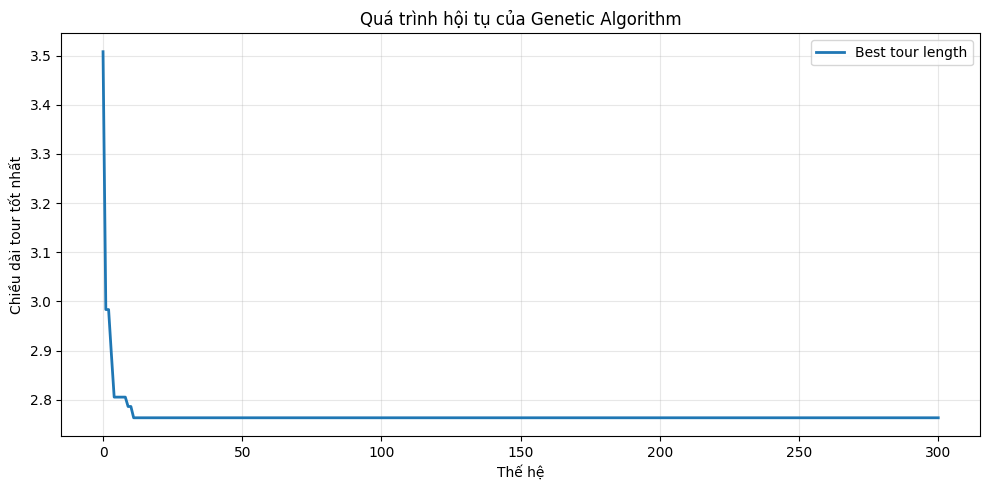

In [20]:
# BONUS - BIỂU ĐỒ HỘI TỤ GENETIC ALGORITHM

plt.figure(figsize=(10, 5))

plt.plot(
    range(len(result_ga["history"])),
    result_ga["history"],
    linewidth=2,
    label="Best tour length"
)

plt.title("Quá trình hội tụ của Genetic Algorithm")
plt.xlabel("Thế hệ")
plt.ylabel("Chiều dài tour tốt nhất")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()